# LeetCode #73: Set Matrix Zeroes

https://leetcode.com/problems/set-matrix-zeroes/

## Comparison of Approaches

| Approach | Time | Space | What that means in practice |
| :--- | :--- | :--- | :--- |
| **Brute Force (copy the matrix)** | $O(m \times n)$ | $O(m \times n)$ | Read zeros from a copy, write into the original. A 200×200 matrix means 40,000 extra numbers. |
| **Row and Column Sets** | $O(m \times n)$ | $O(m + n)$ | Remember which rows and columns had a zero: at most 400 entries. |
| **Optimal: First Row/Column as Notes ★** | $O(m \times n)$ | $O(1)$ | The same two passes, with only two true/false flags of extra memory. |

`m` is the number of rows and `n` the number of columns. $O(m \times n)$ means the work grows with the number of squares: about 40,000 steps for the largest 200×200 matrix, a few times over. $O(1)$ space means a fixed amount of extra memory however big the matrix is.

---

## Understanding the Methods

### Brute Force (copy the matrix)
Make a copy. Scan the copy for zeros and, for each one, zero its row and column in the original. Reading from the copy means zeros you just wrote can't trigger more zeroing. Correct, but it doubles the memory.

### Row and Column Sets
One pass records which rows and which columns contain a zero, in two sets. A second pass zeroes every square whose row or column is in a set. Much less memory, but it still grows with the matrix's size.

### Optimal: First Row/Column as Notes ★
The first row has one square per column and the first column one square per row, so they can hold those two sets: `matrix[0][j] = 0` means "zero column `j`" and `matrix[i][0] = 0` means "zero row `i`". Before writing any notes, save two flags saying whether the first row and first column had a zero of their own. Then note the zeros, zero the inner squares from the notes, and only at the end zero the first row and column if their flags say so.

**Why this is better than the sets:** the same time, but no memory that grows with the matrix. The problem's follow-up asks for exactly this.

**Constraints:**
* `m == matrix.length`, `n == matrix[0].length`
* `1 <= m, n <= 200`
* $-2^{31} \leq$ `matrix[i][j]` $\leq 2^{31} - 1$
* Must be done **in place**

## Explain Like I'm a Newbie

### What the question is actually asking

Every 0 in the matrix wipes out its whole row and its whole column. Change the matrix itself; don't return a new one.

```
1 1 1        1 0 1
1 0 1   ->   0 0 0
1 1 1        1 0 1
```

### The one idea you need: decide everything before you change anything

If you zero a row the moment you see a 0, the zeros you just wrote look exactly like real ones. A few squares later you meet one of them, and it wipes its own row and column too. So only the zeros that were there at the start may count. Make one pass that **decides** which rows and columns to wipe, then a second pass that **writes**.

Deciding needs a list of rows and a list of columns. Here's the trick: the first row has exactly one square per column, and the first column has one square per row. So they can be the lists. Writing 0 at the top of column 3 is a note saying "wipe column 3".

But those squares also hold real data. A 0 that was already in the first row must still wipe the first row, and once notes are written you can't tell the two apart. So before writing a single note, check the first row and first column and save the answers in two true/false flags.

### What that means in code

Four steps, and their order is the whole solution:

1. Set `first_row_zero` and `first_col_zero`.
2. For each inner 0 at `(i, j)`, write the notes `matrix[i][0] = 0` and `matrix[0][j] = 0`.
3. Zero every inner square whose row note or column note is 0.
4. Use the two flags to zero the first row and first column.

Step 4 comes last because step 3 is still reading the notes.

### Mistakes people make the first time

1. **Zeroing on sight.** The first sample comes out as `[[1,0,0],[0,0,0],[0,0,0]]`: the new zeros trigger more zeroing.
2. **One corner square for both flags.** Letting `matrix[0][0]` mean "zero row 0" *and* "zero column 0" passes both samples, then turns `[[1,0],[1,1]]` into all zeros. The answer is `[[0,0],[1,0]]`: row 0 had a zero, column 0 didn't.
3. **Marking doomed squares with -1** and clearing them at the end. It passes both samples, but -1 is a legal value, so `[[-1,1],[1,0]]` loses its -1.
4. **Zeroing the first row before step 3.** Every column then looks noted.

### Things worth knowing

The flag check reads the first row and column once more, about 400 extra reads at most. And the matrix is changed in place, so if the caller needed the original, that's on them.

## Talking It Through in an Interview

*Written from the interviewer's chair. This is what I'd want to hear from you, from the moment I show you the problem to the moment the code is on the board.*

---

### The thirty-second version

Where you should end up: *"Two passes: decide which rows and columns to wipe, then wipe them, so the zeros I write can't trigger more. To store the decision without extra memory, I use the first row and first column as the notes, after saving two flags that say whether they had zeros of their own. The first row and column are wiped last, because they're being read until then. $O(mn)$ time, $O(1)$ extra space."*

And then: *"honestly, the version with two sets is easier to read and only costs $O(m + n)$. I'd write the in-place one because you asked for constant space."*

---

### I slide the problem across the table

> **You:** "So any 0 zeroes its row and column. Do zeros that I create count? If I zero row 1 and that puts a 0 in column 2, does column 2 get wiped too?"

That's the question I'm hoping for. It's the whole difficulty in one sentence. I'll say **"no, only the zeros in the original matrix count."**

> **You:** "And in place. Is extra memory allowed at all, or are you after constant space?"

**"Get it working however you like, then tell me if you can do it in constant space."** That's the follow-up written into the problem, and asking means you'll plan for it instead of being surprised.

What I don't want is *"can the matrix be empty?"*: the constraints say at least 1×1.

---

### Now tell me what's actually hard about it

If you say "use the first row as a marker" first, I'll assume you've memorised it.

> **You:** "The hard part is that writing destroys information. As soon as I write a 0, it's indistinguishable from an original 0. Zero-on-sight cascades: on your first example I'd end up with `[[1,0,0],[0,0,0],[0,0,0]]`. So I have to separate deciding from writing. Deciding is just two lists, which rows and which columns, so $O(m + n)$ with two sets is easy."

> **You:** "For constant space I need somewhere in the matrix to keep those lists. The first row has one square per column and the first column one per row, so they fit exactly. The cost is that they hold real values too, so I save whether they had zeros before I overwrite anything."

That's the reasoning I want: the trick arrives as the answer to a storage problem.

I'll usually push: *why not mark the doomed squares with something like -1 and clean up later?*

> **You:** "Any integer is legal, -1 included, so a sentinel can collide with real data. Writing zeros as the notes is safe because a square that gets a note is a square that's being zeroed anyway."

That last clause is the reason the trick is correct, and few candidates say it.

---

### Before you touch the board, tell me the shape and the cost

> **You:** "Check the first row and first column for zeros: $m + n$ reads. One pass over the inner squares writing notes, one more pass zeroing from the notes, then at most one row and one column. Each pass is $O(mn)$, so $O(mn)$ overall, around 80,000 square visits for a 200×200 matrix. Extra memory is two booleans."

---

### Now whiteboard it

```
first_row_zero = any(matrix[0][j] == 0 for j in range(n))
first_col_zero = any(matrix[i][0] == 0 for i in range(m))
```

> **You:** "Two flags, not one. The first row and first column only share the corner square, and they can disagree."

If you use `matrix[0][0]` for both, I'll hand you `[[1,0],[1,1]]`: row 0 needs wiping, column 0 doesn't, and the corner can't say both.

```
for i in 1..m-1:
    for j in 1..n-1:
        if matrix[i][j] == 0:
            matrix[i][0] = 0
            matrix[0][j] = 0
```

> **You:** "Both loops start at 1. The first row and column are the notepad, and their own zeros are already in the flags."

```
for i in 1..m-1:
    for j in 1..n-1:
        if matrix[i][0] == 0 or matrix[0][j] == 0:
            matrix[i][j] = 0
if first_row_zero: zero row 0
if first_col_zero: zero column 0
```

> **You:** "The notepad is wiped last. If I zeroed the first row before this loop, every column would look noted and I'd wipe everything."

Without that sentence I'd ask *"what if you swapped the last two blocks with the loop above them?"*

---

### Walk me through it before you say you're done

> **You:** "Your second example, `[[0,1,2,0],[3,4,5,2],[1,3,1,5]]`. The first row has zeros, so `first_row_zero` is true. The first column starts with a 0, so `first_col_zero` is true too. No inner zeros, so no notes are written. In the second pass, the top of column 3 is already 0, an original zero that doubles as a note, so the 2 and the 5 in column 3 become 0. Then the flags wipe row 0 and column 0. Result `[[0,0,0,0],[0,4,5,0],[0,3,1,0]]`."

Then the clarifier, tied back:

> **You:** "None of the zeros I wrote in that pass were ever read as a reason to zero something else. That's the 'only original zeros count' answer you gave me."

---

### Then tell me where it breaks, before I ask

It's optimal, so this beat is about what it leans on:

> **You:** "It relies on the change being 'write a zero'. The note and the final value are the same thing, which is why noting a square in the first row never loses information I still need. If you asked me to fill rows with, say, the row's maximum, the notes would destroy values I need to read, and I'd be back to $O(m + n)$ extra memory."

> **You:** "And it's a contract cost: your matrix is modified in place, including while I'm halfway through. If another thread reads it mid-way, it sees notes, not answers."

---

### What would worry me

- **Zeroing on sight** and not noticing the cascade until the dry run.
- **One flag for both the first row and the first column.**
- **A sentinel value** in a problem whose values cover the whole integer range.
- **Wiping the first row or column before the inner pass** has finished reading them.

## Solutions

### C#

In [ ]:
public class Solution {
    public void SetZeroes(int[][] matrix) {
        int m = matrix.Length, n = matrix[0].Length;

        // The first row and column are about to become notes ("zero this column / this row").
        // Save whether they had a 0 of their OWN first; afterwards the two look the same.
        // Two flags, not one: row 0 and column 0 share only the corner and can disagree
        bool firstRowZero = false, firstColZero = false;
        for (int j = 0; j < n; j++) if (matrix[0][j] == 0) firstRowZero = true;
        for (int i = 0; i < m; i++) if (matrix[i][0] == 0) firstColZero = true;

        // Pass 1: decide. For each inner 0, write a note at the start of its row and the top of its column.
        // Writing 0 as the note is safe: that square is going to be 0 anyway
        for (int i = 1; i < m; i++)
            for (int j = 1; j < n; j++)
                if (matrix[i][j] == 0) {
                    matrix[i][0] = 0;
                    matrix[0][j] = 0;
                }

        // Pass 2: write. Zero every inner square whose row or column was noted
        for (int i = 1; i < m; i++)
            for (int j = 1; j < n; j++)
                if (matrix[i][0] == 0 || matrix[0][j] == 0)
                    matrix[i][j] = 0;

        // Last: the notes are no longer needed, so wipe the first row/column if they had their own 0
        if (firstRowZero) for (int j = 0; j < n; j++) matrix[0][j] = 0;
        if (firstColZero) for (int i = 0; i < m; i++) matrix[i][0] = 0;
    }
}

### Python

In [ ]:
class Solution:
    def setZeroes(self, matrix: list[list[int]]) -> None:
        m, n = len(matrix), len(matrix[0])

        # The first row and column are about to become notes ("zero this
        # column / this row"). Save whether they had a 0 of their OWN first;
        # afterwards the two look the same. Two flags, not one: row 0 and
        # column 0 share only the corner and can disagree.
        first_row_zero = any(matrix[0][j] == 0 for j in range(n))
        first_col_zero = any(matrix[i][0] == 0 for i in range(m))

        # Pass 1: decide. For each inner 0, write a note at the start of its
        # row and the top of its column. Writing 0 as the note is safe: that
        # square is going to be 0 anyway.
        for i in range(1, m):
            for j in range(1, n):
                if matrix[i][j] == 0:
                    matrix[i][0] = 0
                    matrix[0][j] = 0

        # Pass 2: write. Zero every inner square whose row or column was noted
        for i in range(1, m):
            for j in range(1, n):
                if matrix[i][0] == 0 or matrix[0][j] == 0:
                    matrix[i][j] = 0

        # Last: the notes are no longer needed, so wipe the first row/column
        # if they had their own 0
        if first_row_zero:
            for j in range(n): matrix[0][j] = 0
        if first_col_zero:
            for i in range(m): matrix[i][0] = 0

### Go

In [ ]:
func setZeroes(matrix [][]int) {
    m, n := len(matrix), len(matrix[0])

    // The first row and column are about to become notes ("zero this column / this row").
    // Save whether they had a 0 of their OWN first; afterwards the two look the same.
    // Two flags, not one: row 0 and column 0 share only the corner and can disagree
    firstRowZero, firstColZero := false, false
    for j := 0; j < n; j++ {
        if matrix[0][j] == 0 {
            firstRowZero = true
        }
    }
    for i := 0; i < m; i++ {
        if matrix[i][0] == 0 {
            firstColZero = true
        }
    }

    // Pass 1: decide. For each inner 0, write a note at the start of its row and the top of its column.
    // Writing 0 as the note is safe: that square is going to be 0 anyway
    for i := 1; i < m; i++ {
        for j := 1; j < n; j++ {
            if matrix[i][j] == 0 {
                matrix[i][0] = 0
                matrix[0][j] = 0
            }
        }
    }

    // Pass 2: write. Zero every inner square whose row or column was noted
    for i := 1; i < m; i++ {
        for j := 1; j < n; j++ {
            if matrix[i][0] == 0 || matrix[0][j] == 0 {
                matrix[i][j] = 0
            }
        }
    }

    // Last: the notes are no longer needed, so wipe the first row/column if they had their own 0
    if firstRowZero {
        for j := 0; j < n; j++ {
            matrix[0][j] = 0
        }
    }
    if firstColZero {
        for i := 0; i < m; i++ {
            matrix[i][0] = 0
        }
    }
}

### Rust

In [ ]:
impl Solution {
    pub fn set_zeroes(matrix: &mut Vec<Vec<i32>>) {
        let m = matrix.len();
        let n = matrix[0].len();

        // The first row and column are about to become notes ("zero this column / this row").
        // Save whether they had a 0 of their OWN first; afterwards the two look the same.
        // Two flags, not one: row 0 and column 0 share only the corner and can disagree
        let first_row_zero = (0..n).any(|j| matrix[0][j] == 0);
        let first_col_zero = (0..m).any(|i| matrix[i][0] == 0);

        // Pass 1: decide. For each inner 0, write a note at the start of its row and the top of its column.
        // Writing 0 as the note is safe: that square is going to be 0 anyway
        for i in 1..m {
            for j in 1..n {
                if matrix[i][j] == 0 {
                    matrix[i][0] = 0;
                    matrix[0][j] = 0;
                }
            }
        }

        // Pass 2: write. Zero every inner square whose row or column was noted
        for i in 1..m {
            for j in 1..n {
                if matrix[i][0] == 0 || matrix[0][j] == 0 {
                    matrix[i][j] = 0;
                }
            }
        }

        // Last: the notes are no longer needed, so wipe the first row/column if they had their own 0
        if first_row_zero { for j in 0..n { matrix[0][j] = 0; } }
        if first_col_zero { for i in 0..m { matrix[i][0] = 0; } }
    }
}

## Example Scenarios

### 1. Common Case — One Zero in the Middle
**Input:** `matrix = [[1,1,1],[1,0,1],[1,1,1]]`

Neither flag is set: the first row and column have no zeros. The 0 at `(1,1)` writes a note at the start of row 1 and the top of column 1, and the second pass zeroes the rest of that row and column. **Output:** `[[1,0,1],[0,0,0],[1,0,1]]`

### 2. Slightly Complex — Zeros in the First Row
**Input:** `matrix = [[0,1,2,0],[3,4,5,2],[1,3,1,5]]`

Both flags are set, because the corner is 0. There are no inner zeros, but the 0 at the top of column 3 is already a note, so the inner squares of column 3 are zeroed. Then the flags wipe row 0 and column 0. **Output:** `[[0,0,0,0],[0,4,5,0],[0,3,1,0]]`

### 3. Edge Case: Time Factor — Largest Matrix, Zero in the Last Square
**Input:** a $200 \times 200$ matrix of 1s, except `matrix[199][199] = 0`

Both passes visit all $199 \times 199 \approx 40{,}000$ inner squares, plus the flag checks: the most work this size allows. The single 0 notes row 199 and column 199, and only those get wiped. **Output:** the same matrix with row 199 and column 199 all 0

### 4. Edge Case: Space Factor — Nothing to Zero
**Input:** a $200 \times 200$ matrix of 1s

No flag is set and no note is written, so the matrix comes back unchanged. The extra memory is still just the two flags; with the sets approach it would have been two empty sets of up to 200 entries each. **Output:** the same matrix, unchanged

### 5. Almost-Impossible but Plausible — A Single Zero Square
**Input:** `matrix = [[0]]`

The only square is the first row, the first column and the corner at once, so both flags are true. The inner loops don't run at all (there's no row 1 or column 1). The flags then zero a square that is already 0. **Output:** `[[0]]`


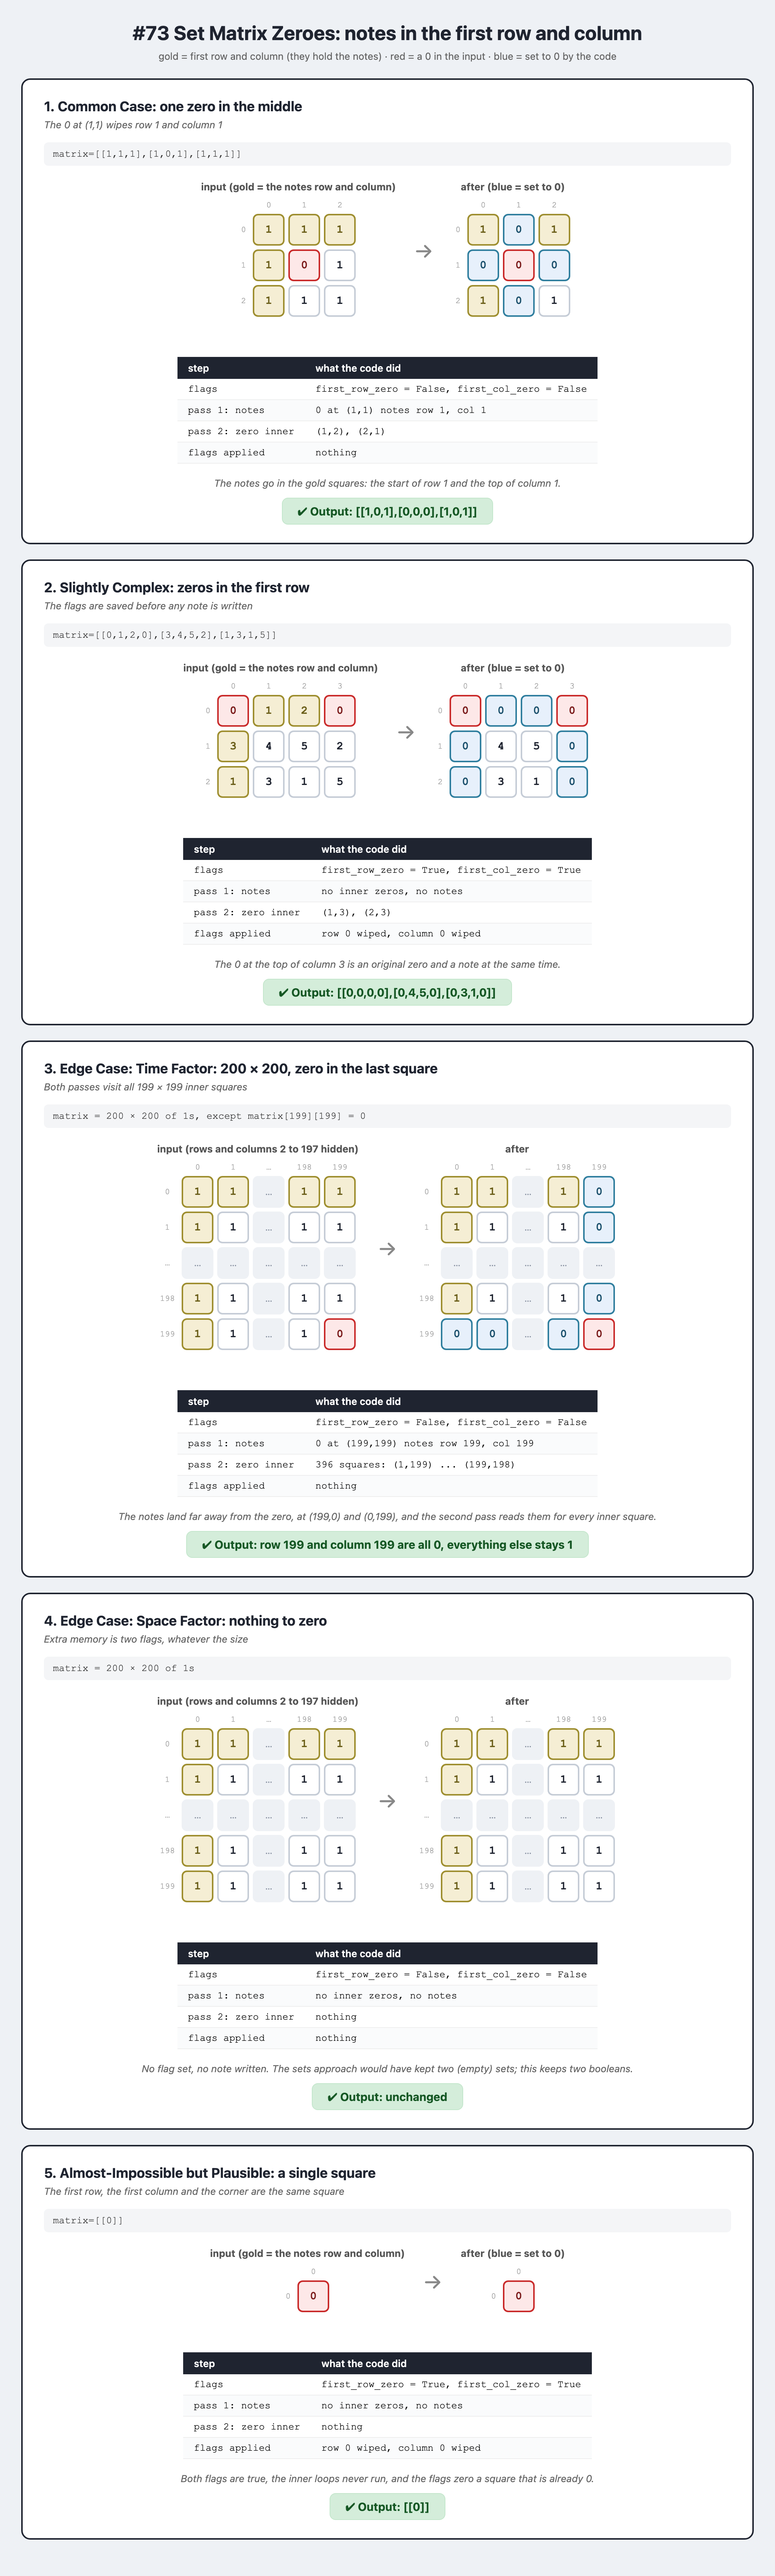

## Watch It Run

*Watch the two flags at the start: they record the first row's and column's own zeros before those cells start holding notes for everyone else.*

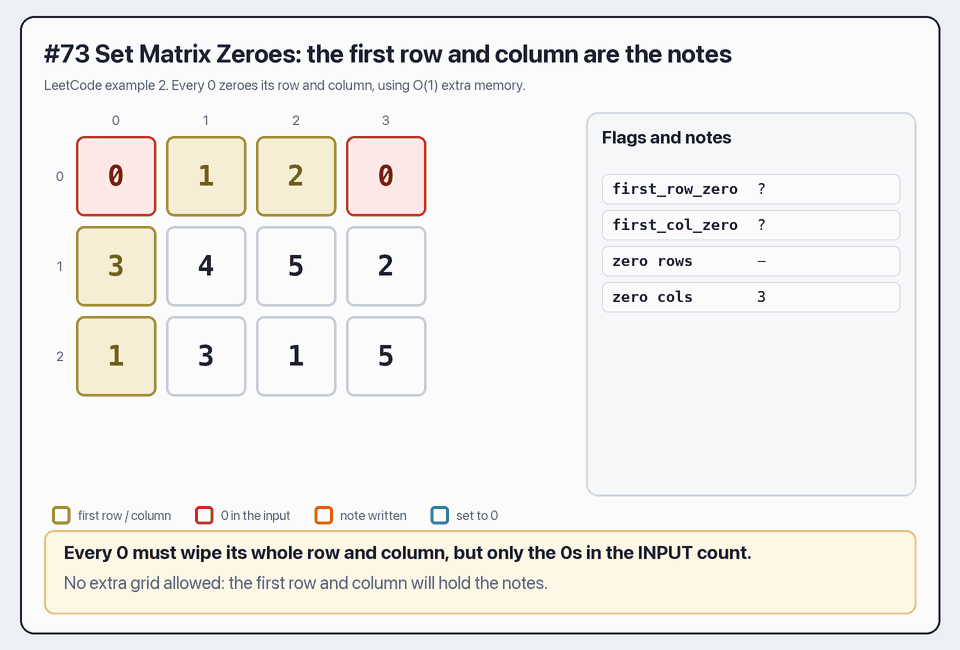

**[Step through it yourself: play, pause, scrub and step through this walkthrough, plus a harder example](https://sanjay-bhat.github.io/ProgrammingConcepts/walkthroughs/0073.html)**